# CSC490 - ConvNeXt-Tiny (A + B) and SAM 2 (B) on the team split

One notebook for all three runs. Runtime: **GPU** (Runtime > Change runtime type).

| Run | Backbone | Benign pairs in training |
|---|---|---|
| `convnext_A` | ConvNeXt-Tiny | no |
| `convnext_B` | ConvNeXt-Tiny | yes |
| `sam2_B` | SAM 2 Hiera-Tiny | yes |

Run all cells top to bottom. Each finished model is saved to Drive (`CSC490_data/checkpoints/`), so a rerun **skips training** for any model that already exists. Predictions are written in the team format (`docs/prediction-format.md`) to `CSC490_data/predictions/`, and poster charts go to `CSC490_data/figures/poster/`.

In [2]:
# ---- 0. setup ----
from google.colab import drive
drive.mount("/content/drive")
!pip -q install -U timm

Mounted at /content/drive


In [3]:
# ---- 1. settings (the only cell you may need to edit) ----
ZIP_ON_DRIVE = "/content/drive/MyDrive/CSC490_data/d2c_v3.zip"
SPLIT_JSON   = "/content/drive/MyDrive/CSC490_data/splits_85_15.json"   # team split (390 / 69 / 25 pages)
DATA_ROOT    = "/content/d2c_v2"
OUT_ROOT     = "/content/drive/MyDrive/CSC490_data"
CKPT_DIR     = f"{OUT_ROOT}/checkpoints"
PRED_DIR     = f"{OUT_ROOT}/predictions"
FIG_DIR      = f"{OUT_ROOT}/figures/poster"

RUNS = [  # name, backbone, include benign in training
    ("convnext_A", "convnext", False),
    ("convnext_B", "convnext", True),
    ("sam2_B",     "sam2",     True),
]
RETRAIN = False          # True = train again even if a checkpoint exists

EPOCHS, BATCH = 8, 8
LR_BACKBONE, LR_HEAD, WARMUP_STEPS = 2e-5, 3e-4, 300
TILE, STRIDE = 512, 384  # training tile size; sliding-window step at inference
SEED = 490

import os
for d in (CKPT_DIR, PRED_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

In [4]:
# ---- 2. data + team split ----
import json, random, shutil, zipfile
from collections import Counter
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

if not os.path.exists(os.path.join(DATA_ROOT, "master_dataset_with_benign.json")):
    print("copying + extracting dataset ...")
    shutil.copy(ZIP_ON_DRIVE, "/content/d2c.zip")
    with zipfile.ZipFile("/content/d2c.zip") as z:
        z.extractall("/content")

ALL_RECS = json.load(open(os.path.join(DATA_ROOT, "master_dataset_with_benign.json")))
SPLIT = json.load(open(SPLIT_JSON))
train_pages, val_pages = set(SPLIT["train"]), set(SPLIT["val"])
excluded_pages = set(SPLIT.get("excluded", []))
assert not (train_pages & val_pages) and not ((train_pages | val_pages) & excluded_pages)

TRAIN_ALL = [r for r in ALL_RECS if r["parent_id"] in train_pages]
VAL_RECS  = [r for r in ALL_RECS if r["parent_id"] in val_pages]   # every pair of every val page
BY_ID = {r["sample_id"]: r for r in ALL_RECS}

print(f"pages  train {len(train_pages)} | val {len(val_pages)} | excluded {len(excluded_pages)}")
print("train", len(TRAIN_ALL), dict(Counter(r["label"] for r in TRAIN_ALL)))
print("val  ", len(VAL_RECS), dict(Counter(r["label"] for r in VAL_RECS)))

NORM = transforms.Compose([transforms.ToTensor(),
                           transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


def load_pair(r):
    """Both screenshots on one white canvas; H_common = rows that both pages really have."""
    ref = Image.open(os.path.join(DATA_ROOT, r["reference_path"])).convert("RGB")
    cand = Image.open(os.path.join(DATA_ROOT, r["candidate_path"])).convert("RGB")
    W = max(ref.width, cand.width, TILE)
    H = max(ref.height, cand.height, TILE)
    H_common = max(min(ref.height, cand.height), TILE)

    def pad(img):
        if img.size == (W, H):
            return img
        c = Image.new("RGB", (W, H), "white"); c.paste(img, (0, 0))
        return c
    return pad(ref), pad(cand), W, H, H_common


class TrainTiles(Dataset):
    """Regression: tile around the change (jittered). Negatives: random tile inside H_common."""
    def __init__(self, recs):
        self.recs = recs

    def __len__(self):
        return len(self.recs)

    def window(self, r, W, Hc):
        T = TILE
        b0, b1 = r.get("bbox_before"), r.get("bbox_after")
        if r["label"] == "regression" and b0 and b1:
            x0, y0 = min(b0[0], b1[0]), min(b0[1], b1[1])
            x1, y1 = max(b0[0] + b0[2], b1[0] + b1[2]), max(b0[1] + b0[3], b1[1] + b1[3])
            cx = (x0 + x1) / 2 + random.uniform(-T / 4, T / 4)
            cy = (y0 + y1) / 2 + random.uniform(-T / 4, T / 4)
            return int(min(max(0, cx - T / 2), W - T)), int(min(max(0, cy - T / 2), max(0, Hc - T)))
        return random.randint(0, W - T), random.randint(0, max(0, Hc - T))

    def __getitem__(self, i):
        r = self.recs[i]
        ref, cand, W, H, Hc = load_pair(r)
        x, y = self.window(r, W, Hc)
        box = (x, y, x + TILE, y + TILE)
        return NORM(ref.crop(box)), NORM(cand.crop(box)), torch.tensor(float(r["label"] == "regression"))

copying + extracting dataset ...
pages  train 390 | val 69 | excluded 25
train 5909 {'no_change': 390, 'regression': 4739, 'benign': 780}
val   1033 {'no_change': 69, 'regression': 826, 'benign': 138}


In [5]:
# ---- 3. model ----
import time
import torch.nn as nn
import torch.nn.functional as F

device = "cuda"
assert torch.cuda.is_available(), "Switch the Colab runtime to a GPU."


class SiameseNet(nn.Module):
    """Shared backbone -> fuse [F_ref, F_cand, |F_ref - F_cand|] per location -> avg+max pool -> 1 logit."""
    def __init__(self, backbone, pretrained=True):
        super().__init__()
        if backbone == "convnext":
            from torchvision import models
            w = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
            self.trunk, ch = models.convnext_tiny(weights=w).features, 768
        else:
            import timm
            self.trunk = timm.create_model("sam2_hiera_tiny.fb_r896", pretrained=pretrained,
                                           features_only=True, out_indices=(-1,))
            ch = self.trunk.feature_info.channels()[-1]
        self.fuse = nn.Sequential(
            nn.Conv2d(ch * 3, 256, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))

    def feat(self, x):
        f = self.trunk(x)
        return f[-1] if isinstance(f, (list, tuple)) else f

    def forward(self, a, b):
        fa, fb = self.feat(a), self.feat(b)
        x = self.fuse(torch.cat([fa, fb, (fa - fb).abs()], 1))
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], 1).flatten(1)
        return self.head(x).squeeze(1)

In [6]:
# ---- 4. train (skipped for any model whose checkpoint already exists) ----
def train_run(name, backbone, include_benign):
    ckpt = f"{CKPT_DIR}/{name}_team.pt"
    if os.path.exists(ckpt) and not RETRAIN:
        print(f"[{name}] checkpoint found, skipping training: {ckpt}")
        return ckpt
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    recs = TRAIN_ALL if include_benign else [r for r in TRAIN_ALL if r["label"] != "benign"]
    loader = DataLoader(TrainTiles(recs), batch_size=BATCH, shuffle=True, drop_last=True,
                        num_workers=2, pin_memory=True)
    model = SiameseNet(backbone).to(device)
    opt = torch.optim.AdamW([
        {"params": model.trunk.parameters(), "lr": LR_BACKBONE},
        {"params": list(model.fuse.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
    ], weight_decay=1e-4)
    total = EPOCHS * len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS) * 0.5 * (1 + np.cos(np.pi * min(1.0, s / total))))
    n_pos = sum(r["label"] == "regression" for r in recs)
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(len(recs) - n_pos) / n_pos], device=device))
    scaler = torch.amp.GradScaler("cuda")
    print(f"[{name}] {len(recs)} train pairs {dict(Counter(r['label'] for r in recs))}, {total} steps")
    history = []
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for i, (a, c, y) in enumerate(loader):
            a, c, y = a.to(device, non_blocking=True), c.to(device, non_blocking=True), y.to(device)
            with torch.autocast("cuda"):
                loss = bce(model(a, c).float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        history.append(tot / n)
        print(f"[{name}] epoch {ep}: loss {tot / n:.4f} | {time.time() - t0:.0f}s")
    # last epoch is kept: val labels are never used for model selection
    torch.save(model.state_dict(), ckpt)
    json.dump(history, open(f"{CKPT_DIR}/{name}_team_loss.json", "w"))
    print(f"[{name}] saved -> {ckpt}")
    del model; torch.cuda.empty_cache()
    return ckpt


CKPTS = {name: train_run(name, bb, ib) for name, bb, ib in RUNS}

[convnext_A] checkpoint found, skipping training: /content/drive/MyDrive/CSC490_data/checkpoints/convnext_A_team.pt
[convnext_B] checkpoint found, skipping training: /content/drive/MyDrive/CSC490_data/checkpoints/convnext_B_team.pt
[sam2_B] checkpoint found, skipping training: /content/drive/MyDrive/CSC490_data/checkpoints/sam2_B_team.pt


In [7]:
# ---- 5. full-page inference on val -> team-format JSONL ----
# Every pair is scanned with 512 tiles inside H_common; no label or bbox is used.
# score = max tile probability, box = that tile, point = its centre.
def tile_starts(length):
    s = list(range(0, max(1, length - TILE + 1), STRIDE))
    if s[-1] != length - TILE:
        s.append(length - TILE)
    return s


@torch.no_grad()
def predict_pair(model, r, name, bs=16):
    ref, cand, W, H, Hc = load_pair(r)
    boxes = [(x, y) for y in tile_starts(Hc) for x in tile_starts(W)]
    probs = []
    for k in range(0, len(boxes), bs):
        ch = boxes[k:k + bs]
        a = torch.stack([NORM(ref.crop((x, y, x + TILE, y + TILE))) for x, y in ch]).to(device)
        c = torch.stack([NORM(cand.crop((x, y, x + TILE, y + TILE))) for x, y in ch]).to(device)
        with torch.autocast("cuda"):
            probs += torch.sigmoid(model(a, c).float()).cpu().tolist()
    j = int(np.argmax(probs)); x, y = boxes[j]
    return {"sample_id": r["sample_id"], "score": float(probs[j]), "op_pred": None,
            "box": [float(x), float(y), float(TILE), float(TILE)],
            "point": [float(x + TILE / 2), float(y + TILE / 2)],
            "model": name, "format_version": 1}


def export_run(name, backbone):
    out = f"{PRED_DIR}/{name}_team_val.jsonl"
    if os.path.exists(out) and not RETRAIN:
        print(f"[{name}] predictions found: {out}")
    else:
        model = SiameseNet(backbone, pretrained=False).to(device)
        model.load_state_dict(torch.load(CKPTS[name], map_location=device)); model.eval()
        t0 = time.time()
        with open(out, "w") as f:
            for i, r in enumerate(VAL_RECS):
                f.write(json.dumps(predict_pair(model, r, name)) + "\n")
                if i % 200 == 0:
                    print(f"  [{name}] {i}/{len(VAL_RECS)} {time.time() - t0:.0f}s")
        del model; torch.cuda.empty_cache()
    preds = [json.loads(l) for l in open(out)]
    ids = [p["sample_id"] for p in preds]
    assert len(ids) == len(set(ids)) and set(ids) == {r["sample_id"] for r in VAL_RECS}, "format check failed"
    print(f"[{name}] {len(preds)} predictions OK -> {out}")
    return {p["sample_id"]: p for p in preds}


PREDS = {name: export_run(name, bb) for name, bb, _ in RUNS}

[convnext_A] predictions found: /content/drive/MyDrive/CSC490_data/predictions/convnext_A_team_val.jsonl
[convnext_A] 1033 predictions OK -> /content/drive/MyDrive/CSC490_data/predictions/convnext_A_team_val.jsonl
[convnext_B] predictions found: /content/drive/MyDrive/CSC490_data/predictions/convnext_B_team_val.jsonl
[convnext_B] 1033 predictions OK -> /content/drive/MyDrive/CSC490_data/predictions/convnext_B_team_val.jsonl
[sam2_B] predictions found: /content/drive/MyDrive/CSC490_data/predictions/sam2_B_team_val.jsonl
[sam2_B] 1033 predictions OK -> /content/drive/MyDrive/CSC490_data/predictions/sam2_B_team_val.jsonl


In [8]:
# ---- 6. metrics (quick in-notebook summary; the team scorer is the official one) ----
from sklearn.metrics import roc_auc_score, roc_curve

LABELS = np.array([r["label"] for r in VAL_RECS])
IS_REG = LABELS == "regression"


def metrics(name, thr=0.5):
    s = np.array([PREDS[name][r["sample_id"]]["score"] for r in VAL_RECS])
    p = s >= thr
    m_rb = IS_REG | (LABELS == "benign")
    out = {
        "AUROC reg vs benign": roc_auc_score(IS_REG[m_rb], s[m_rb]),
        "AUROC reg vs all": roc_auc_score(IS_REG, s),
        "recall": p[IS_REG].mean(),
        "precision": p[IS_REG].sum() / max(1, p.sum()),
        "FPR benign": p[LABELS == "benign"].mean(),
        "FPR no_change": p[LABELS == "no_change"].mean(),
    }
    out["F1"] = 2 * out["precision"] * out["recall"] / max(1e-9, out["precision"] + out["recall"])
    t95 = np.quantile(s[IS_REG], 0.05)                 # threshold that keeps 95% recall
    out["benign FPR @95% recall"] = (s[LABELS == "benign"] >= t95).mean()
    return out, s


RESULTS, SCORES = {}, {}
for name, _, _ in RUNS:
    RESULTS[name], SCORES[name] = metrics(name)

import pandas as pd
table = pd.DataFrame(RESULTS).T.round(3)
display(table)
table.to_csv(f"{FIG_DIR}/summary_metrics.csv")

,AUROC reg vs benign,AUROC reg vs all,recall,precision,FPR benign,FPR no_change,F1,benign FPR @95% recall
convnext_A,0.284,0.513,0.901,0.844,1.000,0.000,0.871,1.000
convnext_B,0.950,0.950,0.958,0.926,0.203,0.507,0.942,0.196
sam2_B,0.992,0.995,0.985,0.969,0.188,0.000,0.977,0.022


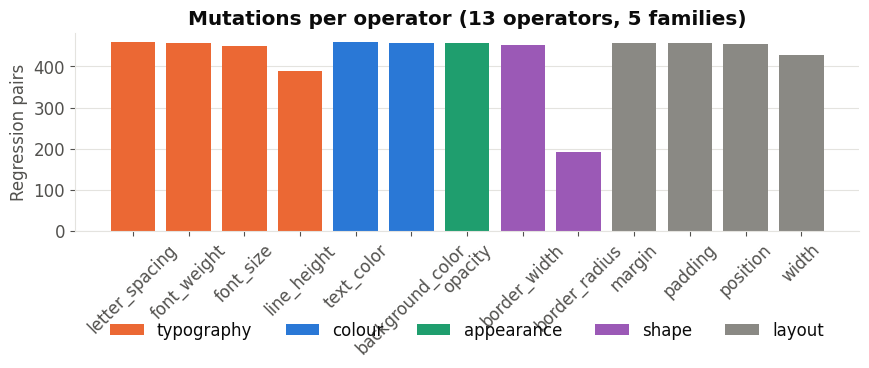

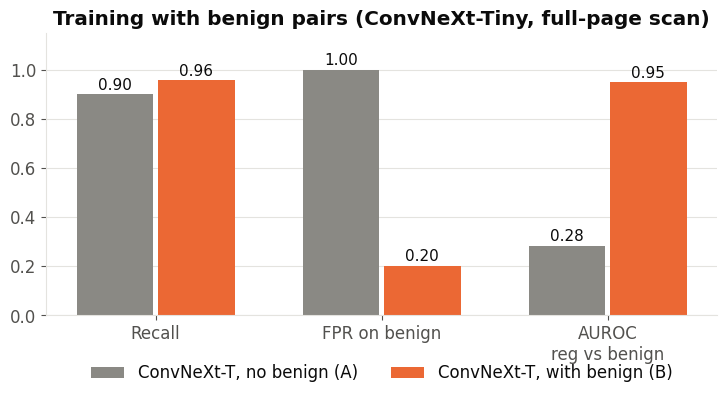

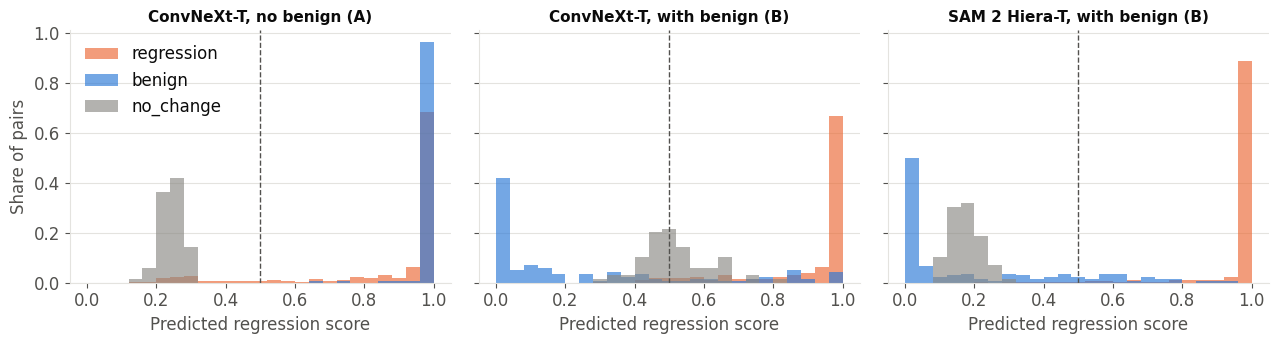

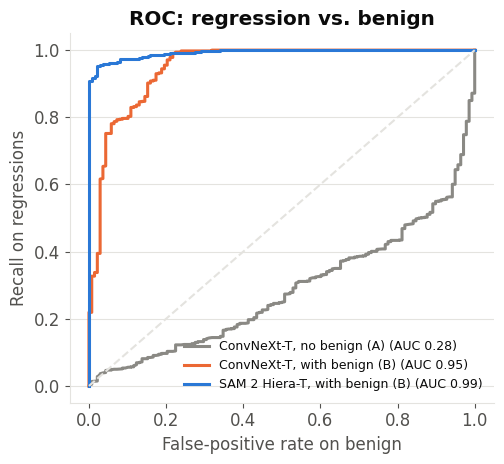

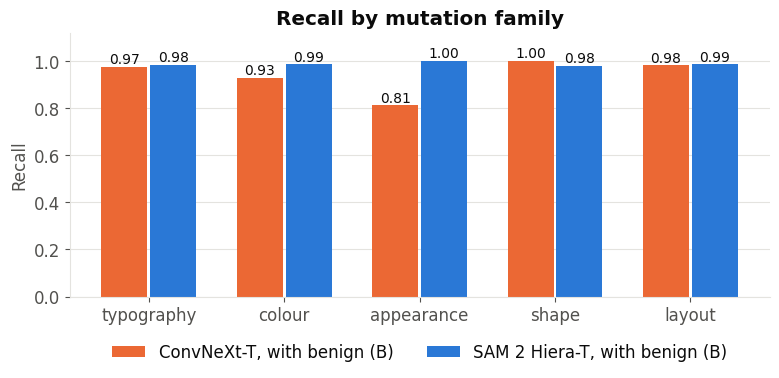

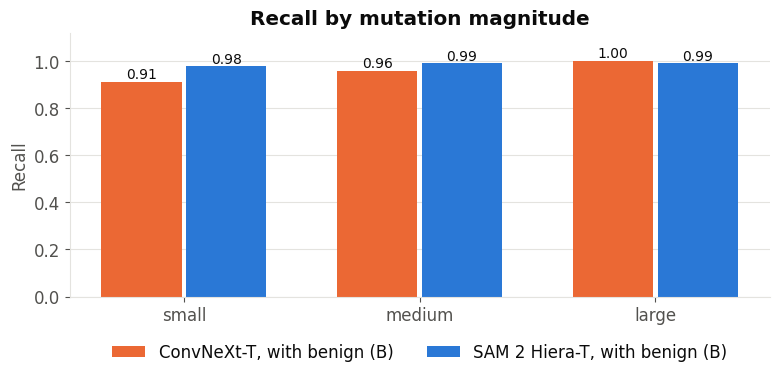

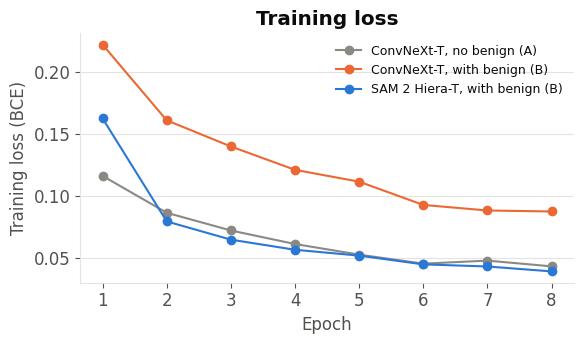

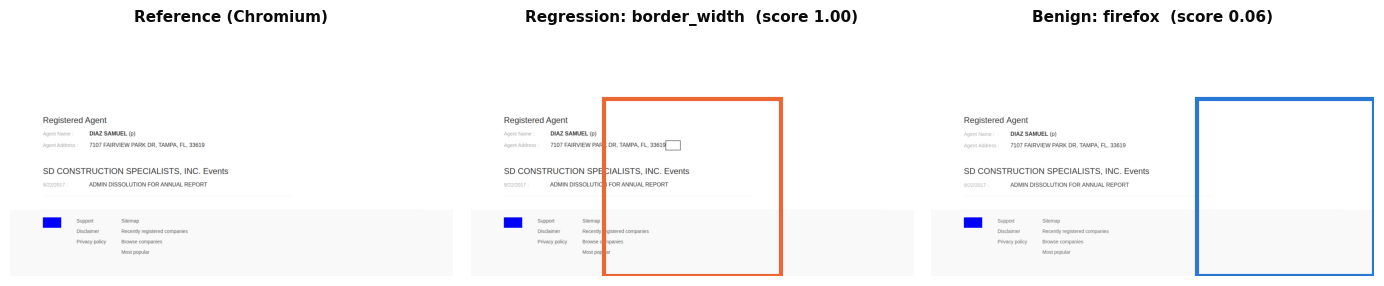

charts saved to /content/drive/MyDrive/CSC490_data/figures/poster


In [ ]:
# ---- 7. poster charts ----
import matplotlib.pyplot as plt
import matplotlib.patches as patches

ORANGE, BLUE, GREEN, GRAY = "#eb6834", "#2a78d6", "#1f9e6e", "#8a8984"
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#ffffff", "#e4e3df"
COL = {"convnext_A": GRAY, "convnext_B": ORANGE, "sam2_B": BLUE}
NICE = {"convnext_A": "ConvNeXt-T, no benign (A)", "convnext_B": "ConvNeXt-T, with benign (B)",
        "sam2_B": "SAM 2 Hiera-T, with benign (B)"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.edgecolor": GRID, "font.size": 12, "axes.titleweight": "bold"})


def clean(ax, grid_axis="y"):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    (ax.yaxis if grid_axis == "y" else ax.xaxis).grid(True, color=GRID); ax.set_axisbelow(True)


def save(fig, fname):
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/{fname}", dpi=300); plt.show()


# 7a. dataset composition: pairs per operator, coloured by family
FAM_COL = {"typography": "#eb6834", "colour": "#2a78d6", "appearance": "#1f9e6e",
           "shape": "#9b59b6", "layout": "#8a8984"}
reg = [r for r in ALL_RECS if r["label"] == "regression" and r["parent_id"] not in excluded_pages]
op_cnt = Counter(r["operator"] for r in reg)
op_fam = {r["operator"]: r["family"] for r in reg}
ops = sorted(op_cnt, key=lambda o: (list(FAM_COL).index(op_fam[o]), -op_cnt[o]))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(ops, [op_cnt[o] for o in ops], color=[FAM_COL[op_fam[o]] for o in ops])
ax.set_ylabel("Regression pairs"); ax.set_title("Mutations per operator (13 operators, 5 families)")
ax.tick_params(axis="x", rotation=45)
for lab, c in FAM_COL.items():
    ax.bar(0, 0, color=c, label=lab)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.38))
clean(ax); save(fig, "1_dataset_operators.png")

# 7b. the key result: A vs B (ConvNeXt) on benign FPR and recall
mets = [("Recall", "recall"), ("FPR on benign", "FPR benign"), ("AUROC\nreg vs benign", "AUROC reg vs benign")]
fig, ax = plt.subplots(figsize=(7.5, 4.2)); x = np.arange(len(mets)); w = 0.36
for k, name in enumerate(["convnext_A", "convnext_B"]):
    v = [RESULTS[name][m] for _, m in mets]
    bars = ax.bar(x + (k - 0.5) * w, v, w - 0.02, color=COL[name], label=NICE[name])
    for b_, vv in zip(bars, v):
        ax.text(b_.get_x() + b_.get_width() / 2, vv + 0.02, f"{vv:.2f}", ha="center", fontsize=11)
ax.set_xticks(x, [m for m, _ in mets]); ax.set_ylim(0, 1.15)
ax.set_title("Training with benign pairs (ConvNeXt-Tiny, full-page scan)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
clean(ax); save(fig, "2_A_vs_B.png")

# 7c. score distributions per true label (shows WHY B is better)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
bins = np.linspace(0, 1, 26)
for ax, (name, _, _) in zip(axes, RUNS):
    for lab, c in [("regression", ORANGE), ("benign", BLUE), ("no_change", GRAY)]:
        ax.hist(SCORES[name][LABELS == lab], bins=bins, color=c, alpha=0.65, label=lab,
                weights=np.ones((LABELS == lab).sum()) / (LABELS == lab).sum())
    ax.axvline(0.5, color=INK2, ls="--", lw=1); ax.set_title(NICE[name], fontsize=11)
    ax.set_xlabel("Predicted regression score"); clean(ax)
axes[0].set_ylabel("Share of pairs"); axes[0].legend(frameon=False)
save(fig, "3_score_distributions.png")

# 7d. ROC, regression vs benign
fig, ax = plt.subplots(figsize=(5.2, 4.8))
m_rb = IS_REG | (LABELS == "benign")
for name, _, _ in RUNS:
    fpr, tpr, _ = roc_curve(IS_REG[m_rb], SCORES[name][m_rb])
    ax.plot(fpr, tpr, color=COL[name], lw=2.2,
            label=f"{NICE[name]} (AUC {RESULTS[name]['AUROC reg vs benign']:.2f})")
ax.plot([0, 1], [0, 1], color=GRID, ls="--")
ax.set_xlabel("False-positive rate on benign"); ax.set_ylabel("Recall on regressions")
ax.set_title("ROC: regression vs. benign"); ax.legend(frameon=False, fontsize=9, loc="lower right")
clean(ax); save(fig, "4_roc_reg_vs_benign.png")

# 7e. recall by family and by magnitude: ConvNeXt B vs SAM 2 B
def recall_by(name, key, thr=0.5):
    g = {}
    for r, s in zip(VAL_RECS, SCORES[name]):
        if r["label"] == "regression":
            g.setdefault(r[key], []).append(s >= thr)
    return {k: np.mean(v) for k, v in g.items()}

for key, order, fname in [("family", list(FAM_COL), "5_recall_by_family.png"),
                          ("magnitude", ["small", "medium", "large"], "6_recall_by_magnitude.png")]:
    fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(len(order)); w = 0.36
    for k, name in enumerate(["convnext_B", "sam2_B"]):
        rb = recall_by(name, key); v = [rb.get(o, np.nan) for o in order]
        bars = ax.bar(x + (k - 0.5) * w, v, w - 0.02, color=COL[name], label=NICE[name])
        for b_, vv in zip(bars, v):
            ax.text(b_.get_x() + b_.get_width() / 2, vv + 0.015, f"{vv:.2f}", ha="center", fontsize=10)
    ax.set_xticks(x, order); ax.set_ylim(0, 1.12); ax.set_ylabel("Recall")
    ax.set_title(f"Recall by mutation {key}")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    clean(ax); save(fig, fname)

# 7f. training loss curves
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, _, _ in RUNS:
    p = f"{CKPT_DIR}/{name}_team_loss.json"
    if os.path.exists(p):
        h = json.load(open(p)); ax.plot(range(1, len(h) + 1), h, "o-", color=COL[name], label=NICE[name])
ax.set_xlabel("Epoch"); ax.set_ylabel("Training loss (BCE)"); ax.set_title("Training loss")
ax.legend(frameon=False, fontsize=9); clean(ax); save(fig, "7_training_loss.png")

# 7g. qualitative example: one regression and one benign pair, best model's detected tile
best = max(RESULTS, key=lambda n: RESULTS[n]["AUROC reg vs benign"])
reg_hit = max((r for r in VAL_RECS if r["label"] == "regression" and r["magnitude"] == "medium"),
              key=lambda r: PREDS[best][r["sample_id"]]["score"])
ben = next(r for r in VAL_RECS if r["label"] == "benign" and r["parent_id"] == reg_hit["parent_id"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (r, img_key, title) in zip(axes, [
        (reg_hit, "reference_path", "Reference (Chromium)"),
        (reg_hit, "candidate_path", f"Regression: {reg_hit['operator']}"),
        (ben, "candidate_path", f"Benign: {ben.get('browser_cand', 'other engine')}")]):
    p = PREDS[best][r["sample_id"]]; bx, by, bw, bh = p["box"]
    im = Image.open(os.path.join(DATA_ROOT, r[img_key])).convert("RGB")
    crop = (0, max(0, int(by) - 200), im.width, min(im.height, int(by + bh) + 200))
    ax.imshow(im.crop(crop)); ax.axis("off")
    if img_key == "candidate_path":
        ax.add_patch(patches.Rectangle((bx, by - crop[1]), bw, bh, fill=False, lw=3,
                                       ec=ORANGE if r["label"] == "regression" else BLUE))
        title += f"  (score {p['score']:.2f})"
    ax.set_title(title, fontsize=11)
save(fig, "8_example_detection.png")
print("charts saved to", FIG_DIR)

In [ ]:
# ---- 8. package models + predictions + charts for download ----
import shutil
from google.colab import files

bundle = "/content/csc490_models_and_results"
shutil.rmtree(bundle, ignore_errors=True)
os.makedirs(bundle)
for name, _, _ in RUNS:
    shutil.copy(CKPTS[name], bundle)
    shutil.copy(f"{PRED_DIR}/{name}_team_val.jsonl", bundle)
shutil.copytree(FIG_DIR, f"{bundle}/figures")
zip_path = shutil.make_archive(bundle, "zip", bundle)
print(f"{zip_path}: {os.path.getsize(zip_path) / 1e6:.0f} MB")
files.download(zip_path)   # the same files also stay on Drive

/content/csc490_models_and_results.zip: 321 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Official scoring (team scorer)

```
!git clone https://github.com/<OWNER>/csc490-project.git /content/csc490-project
%cd /content/csc490-project
!pip -q install -e ".[evaluation]"
!python scripts/score_predictions.py --help
!python scripts/score_predictions.py \
    /content/drive/MyDrive/CSC490_data/predictions/convnext_A_team_val.jsonl \
    /content/drive/MyDrive/CSC490_data/predictions/convnext_B_team_val.jsonl \
    /content/drive/MyDrive/CSC490_data/predictions/sam2_B_team_val.jsonl \
    --names convnext_A convnext_B sam2_B --out /content/drive/MyDrive/CSC490_data/comparison
```

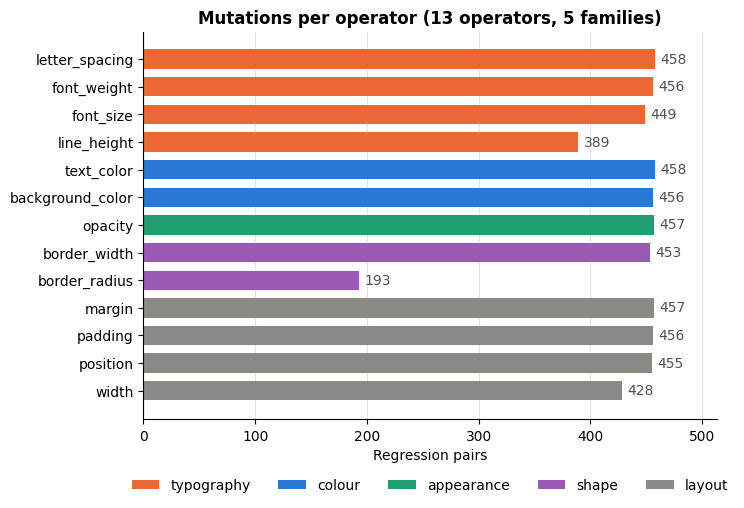

In [11]:
# ---- redo chart 1: horizontal bars, no overlapping labels ----
import matplotlib.pyplot as plt
from collections import Counter

FAM_COL = {"typography": "#eb6834", "colour": "#2a78d6", "appearance": "#1f9e6e",
           "shape": "#9b59b6", "layout": "#8a8984"}
reg = [r for r in ALL_RECS if r["label"] == "regression" and r["parent_id"] not in excluded_pages]
op_cnt = Counter(r["operator"] for r in reg)
op_fam = {r["operator"]: r["family"] for r in reg}
# grouped by family, top to bottom
ops = sorted(op_cnt, key=lambda o: (list(FAM_COL).index(op_fam[o]), -op_cnt[o]))[::-1]

fig, ax = plt.subplots(figsize=(7.5, 5.2))
bars = ax.barh(ops, [op_cnt[o] for o in ops], color=[FAM_COL[op_fam[o]] for o in ops], height=0.7)
for b, o in zip(bars, ops):
    ax.text(b.get_width() + 5, b.get_y() + b.get_height() / 2, str(op_cnt[o]),
            va="center", fontsize=10, color="#52514e")
for fam, c in FAM_COL.items():
    ax.barh([ops[0]], [0], color=c, label=fam)
ax.set_xlabel("Regression pairs")
ax.set_xlim(0, max(op_cnt.values()) * 1.12)
ax.set_title("Mutations per operator (13 operators, 5 families)", fontweight="bold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.xaxis.grid(True, color="#e4e3df"); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/1_dataset_operators.png", dpi=300)
plt.show()

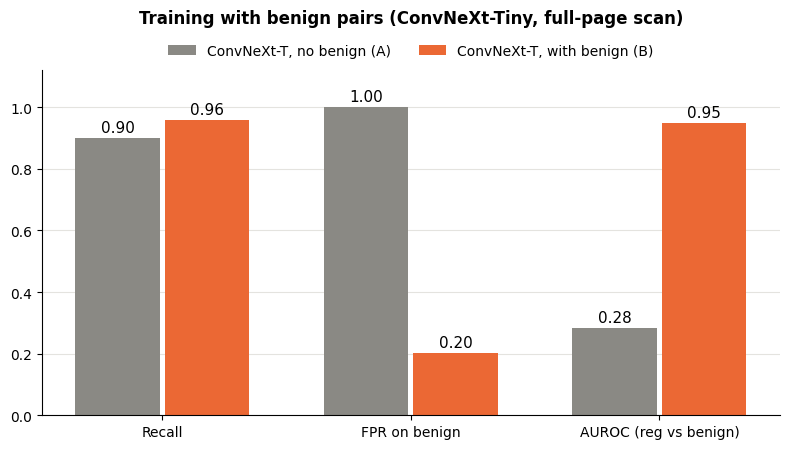

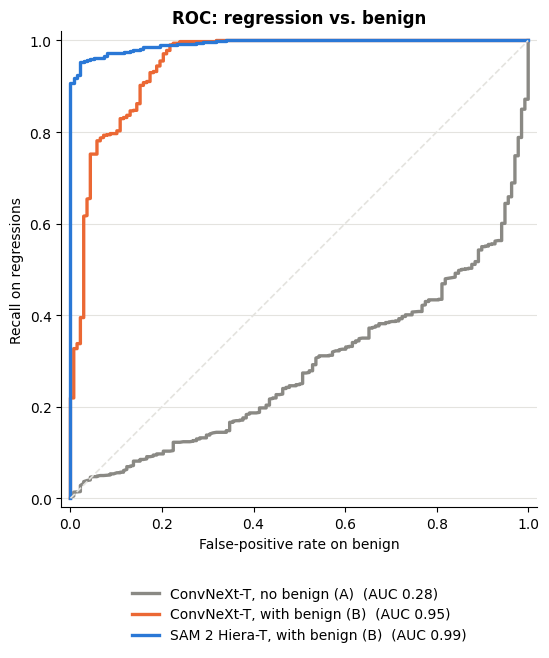

In [10]:
# ---- redo chart 2 (A vs B) and chart 4 (ROC): no overlapping text ----
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

GRAY, ORANGE, BLUE = "#8a8984", "#eb6834", "#2a78d6"
INK2, GRID = "#52514e", "#e4e3df"
COL = {"convnext_A": GRAY, "convnext_B": ORANGE, "sam2_B": BLUE}
NICE = {"convnext_A": "ConvNeXt-T, no benign (A)", "convnext_B": "ConvNeXt-T, with benign (B)",
        "sam2_B": "SAM 2 Hiera-T, with benign (B)"}


def clean(ax, axis="y"):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    (ax.yaxis if axis == "y" else ax.xaxis).grid(True, color=GRID)
    ax.set_axisbelow(True)


# chart 2: legend moved above the bars, one-line tick labels
mets = [("Recall", "recall"), ("FPR on benign", "FPR benign"), ("AUROC (reg vs benign)", "AUROC reg vs benign")]
fig, ax = plt.subplots(figsize=(8, 4.6))
x, w = np.arange(len(mets)), 0.36
for k, name in enumerate(["convnext_A", "convnext_B"]):
    v = [RESULTS[name][m] for _, m in mets]
    bars = ax.bar(x + (k - 0.5) * w, v, w - 0.02, color=COL[name], label=NICE[name])
    for b, vv in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, vv + 0.02, f"{vv:.2f}", ha="center", fontsize=11)
ax.set_xticks(x, [m for m, _ in mets])
ax.set_ylim(0, 1.12)
ax.set_title("Training with benign pairs (ConvNeXt-Tiny, full-page scan)", fontweight="bold", pad=34)
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=10)
clean(ax)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/2_A_vs_B.png", dpi=300)
plt.show()

# chart 4: legend moved below the plot, square axes
fig, ax = plt.subplots(figsize=(5.6, 6.4))
m_rb = IS_REG | (LABELS == "benign")
for name in ["convnext_A", "convnext_B", "sam2_B"]:
    fpr, tpr, _ = roc_curve(IS_REG[m_rb], SCORES[name][m_rb])
    ax.plot(fpr, tpr, color=COL[name], lw=2.4,
            label=f"{NICE[name]}  (AUC {RESULTS[name]['AUROC reg vs benign']:.2f})")
ax.plot([0, 1], [0, 1], color=GRID, ls="--", lw=1.2)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
ax.set_xlabel("False-positive rate on benign"); ax.set_ylabel("Recall on regressions")
ax.set_title("ROC: regression vs. benign", fontweight="bold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=10)
clean(ax)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/4_roc_reg_vs_benign.png", dpi=300)
plt.show()